# Ensembles and Interpretability

A single decision tree is easy to understand but a poor predictor: it overfits, and a small change in the data can produce a completely different tree. The remedy is surprisingly simple – combine many trees. **Ensemble methods** such as random forests and gradient boosting are, for tabular data, among the most accurate general-purpose methods available. In industrial practice they are often the first choice for quality prediction, fault classification and virtual sensors.

Their accuracy comes at a price: an ensemble of hundreds of trees is no longer transparent. Yet engineers need to know *why* a model predicts a defect – to trust it, to check it against physics and to derive process improvements. The second half of this chapter therefore introduces methods to interpret such models.

::: {.scenario}
**Scenario: which defects can be classified automatically?**

The automatic inspection line of a steel mill detects surface defects reliably, but a human inspector still has to assign every defect to a defect class – the class decides whether a plate is reworked, downgraded or scrapped. The inspectors are overloaded. The quality manager proposes to let a model classify those defect classes it recognises reliably and to send only the rest to the inspectors. "Reliable" means: precision and recall of at least 90 % for that class.

**Your decision:** Which defect classes may be classified automatically, and how much inspector workload does that save?
:::

**Learning goals.** After this chapter you can

- explain bagging and boosting and why they improve on a single tree,
- train random forests and gradient boosting models and tune their hyperparameters with cross-validated search,
- solve and evaluate multi-class problems,
- interpret models with permutation importance and partial dependence plots, knowing their limitations,
- (extension) explain individual predictions with SHAP values.

**Datasets in this chapter**

- [Steel Plates Faults (UCI)](https://archive.ics.uci.edu/dataset/198/steel+plates+faults)

## Why ensembles work

Recall the bias–variance decomposition from Chapter 6. A deep decision tree has low bias but high variance. If we could average many trees trained on *different* datasets from the same process, the variance would shrink while the bias stays low. Ensembles approximate this idea in two different ways.

![Bagging and boosting. Bagging trains many deep trees independently on bootstrap samples and averages them (variance reduction). Boosting trains shallow trees one after another, each one correcting the remaining errors of the ensemble so far (bias reduction).](images/bagging-boosting.png){#fig-ensembles width=100%}

### Bagging and random forests

::: {.callout-note}
## Definition: Bagging and random forest
**Bagging** (bootstrap aggregating) trains $B$ models on $B$ bootstrap samples of the training data and averages their predictions (regression) or takes a majority vote (classification).
A **random forest** is bagging with decision trees plus one additional trick: at each split, only a random subset of the features (e.g. $\sqrt{p}$ of $p$ features) is considered. This decorrelates the trees and makes the averaging more effective.
:::

Why the extra randomness helps: averaging $B$ predictions with variance $\sigma^2$ and pairwise correlation $\rho$ gives a variance of $\rho\sigma^2 + \frac{1-\rho}{B}\sigma^2$. More trees reduce only the second term; reducing the correlation $\rho$ between the trees reduces the first. Random forests have few critical hyperparameters, rarely overfit when more trees are added, and provide a free validation estimate: each tree did not see about a third of the data (*out-of-bag* samples), on which it can be evaluated.

### Boosting

::: {.callout-note}
## Definition: Gradient boosting
Gradient boosting builds the model step by step:
$$F_m(x) = F_{m-1}(x) + \nu\, h_m(x),$$
where each new tree $h_m$ is fitted to the negative gradient of the loss with respect to the current predictions – for squared error simply the **residuals** of $F_{m-1}$. The **learning rate** $0 < \nu \le 1$ shrinks each step.
:::

Boosting uses shallow trees (depth 3–8) that individually are weak, and reduces mainly the bias. Unlike random forests, boosting *can* overfit if too many trees are added; the number of trees, the learning rate and the tree depth must be tuned together, typically with early stopping on validation data. Modern implementations (scikit-learn's `HistGradientBoostingClassifier`, XGBoost, LightGBM) are very fast and handle missing values natively.

::: {.callout-tip}
## Engineering practice: which method first?
For a new tabular problem, a random forest with default settings is a robust first model that needs almost no tuning. Gradient boosting is often a few percent more accurate but requires tuning. A linear or logistic model remains the essential baseline – if the ensemble is only marginally better, the simpler model may be preferable for transparency.
:::

## Multi-class problems

With $K > 2$ classes, the confusion matrix becomes $K \times K$, and precision and recall are computed per class. They can be averaged in two ways: the **macro** average treats every class equally (important if rare classes matter), the **weighted** average weights them by their frequency. Balanced accuracy is the macro average of the recalls.

## Interpreting models

::: {.callout-note}
## Definition: Permutation importance
The importance of feature $j$ is the decrease in a performance score (on validation or test data) when the values of feature $j$ are randomly shuffled, which destroys its relationship with the target while keeping its distribution.
:::

Permutation importance works for any model. The impurity-based `feature_importances_` of tree models are cheaper but biased towards features with many distinct values and computed on training data.

::: {.callout-warning}
## Pitfall: importance is not causality – and correlated features share importance
A high importance means that the *model* relies on a feature, not that the feature *causes* the defect. If two features are strongly correlated (e.g. two dimensions of a defect), shuffling one of them hurts little because the other still carries the information – both may appear unimportant although the information is essential.
:::

A **partial dependence plot** (PDP) shows how the predicted probability changes on average when one feature is varied over its range while the others keep their observed values. It answers the engineering question "in which direction and how strongly does this measurement influence the prediction?" and reveals thresholds and nonlinearities.

In [1]:
#| code-fold: false
# Setup: works locally and in Google Colab
import importlib.util, subprocess, sys
for pkg in ["ucimlrepo", "shap"]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

## Live coding: steel plate faults

The dataset comes from the automatic inspection of steel plates. For 1,941 detected surface defects, 27 features were extracted from the inspection images and the production data: position and size of the defect (`X_Minimum`, `Pixels_Areas`, `Length_of_Conveyer`, …), luminosity statistics, shape indices, the steel type and the plate thickness. Each defect belongs to one of seven classes: *Pastry*, *Z_Scratch*, *K_Scatch*, *Stains*, *Dirtiness*, *Bumps* and *Other_Faults*.

In [2]:
#| code-fold: false
from ucimlrepo import fetch_ucirepo

steel = fetch_ucirepo(id=198)
X = steel.data.features
y = steel.data.targets.idxmax(axis=1)      # 7 one-hot columns -> one label
y.value_counts()

Other_Faults    673
Bumps           402
K_Scratch       391
Z_Scratch       190
Pastry          158
Stains           72
Dirtiness        55
Name: count, dtype: int64

The classes are imbalanced: *Other_Faults* is by far the largest class, while *Dirtiness* and *Stains* are rare. "Other faults" is a heterogeneous rest category – we must expect it to be hard to classify.

In [3]:
#| code-fold: false
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=0)
cv = StratifiedKFold(5, shuffle=True, random_state=0)

candidates = {
    "logistic regression (baseline)": make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),
    "random forest": RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=-1),
    "gradient boosting": HistGradientBoostingClassifier(random_state=0),
}
for name, m in candidates.items():
    s = cross_val_score(m, X_train, y_train, cv=cv, scoring="balanced_accuracy")
    print(f"{name:32s} balanced accuracy = {s.mean():.3f} ± {s.std():.3f}")

logistic regression (baseline)   balanced accuracy = 0.717 ± 0.019


random forest                    balanced accuracy = 0.750 ± 0.019


gradient boosting                balanced accuracy = 0.785 ± 0.022


**Discussion.** Both ensembles should clearly outperform the logistic regression baseline. The standard deviation across folds indicates how much of the difference between the ensembles is real – differences smaller than this spread should not be over-interpreted. With seven classes, guessing would reach a balanced accuracy of about 1/7 ≈ 0.14.

              precision    recall  f1-score   support

       Bumps      0.771     0.733     0.751       101
   Dirtiness      0.833     0.714     0.769        14
   K_Scratch      0.967     0.908     0.937        98
Other_Faults      0.692     0.804     0.744       168
      Pastry      0.656     0.538     0.592        39
      Stains      1.000     0.944     0.971        18
   Z_Scratch      0.929     0.812     0.867        48

    accuracy                          0.792       486
   macro avg      0.836     0.779     0.804       486
weighted avg      0.800     0.792     0.793       486



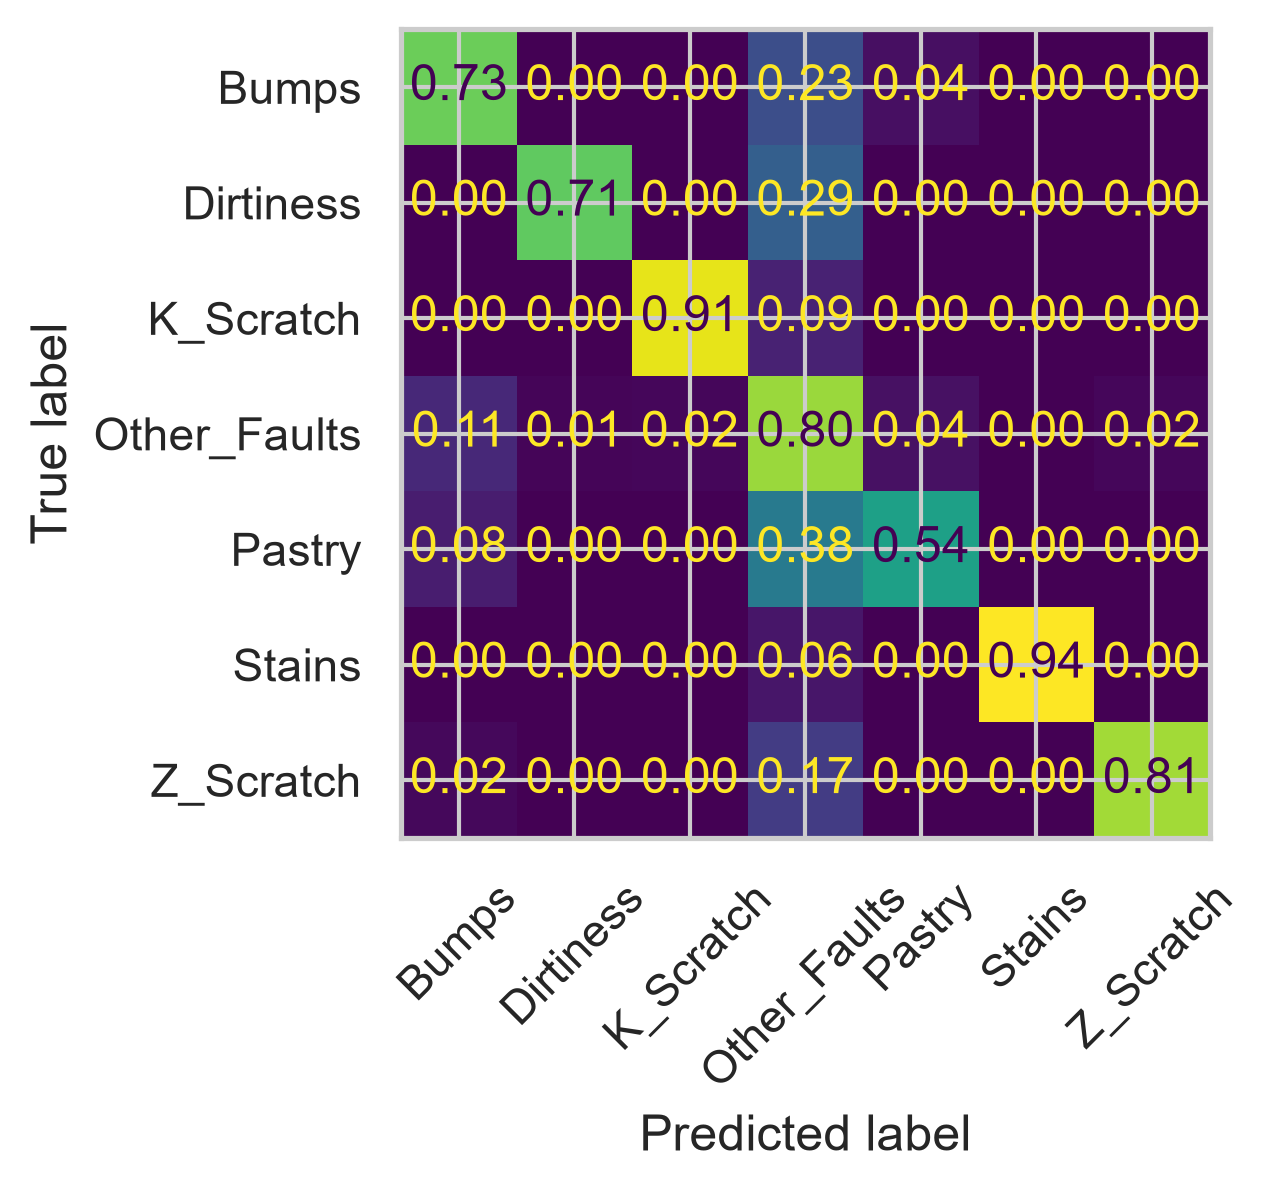

In [4]:
#| code-fold: false
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

rf = candidates["random forest"].fit(X_train, y_train)
print(classification_report(y_test, rf.predict(X_test), digits=3))
ConfusionMatrixDisplay.from_estimator(rf, X_test, y_test, xticks_rotation=45, colorbar=False,
                                      normalize="true", values_format=".2f")
plt.show()

The row-normalised confusion matrix shows for each true class where its defects end up. Typically, geometrically distinctive defects (scratches, pastry) are recognised well, while *Other_Faults* and *Bumps* are confused with each other.

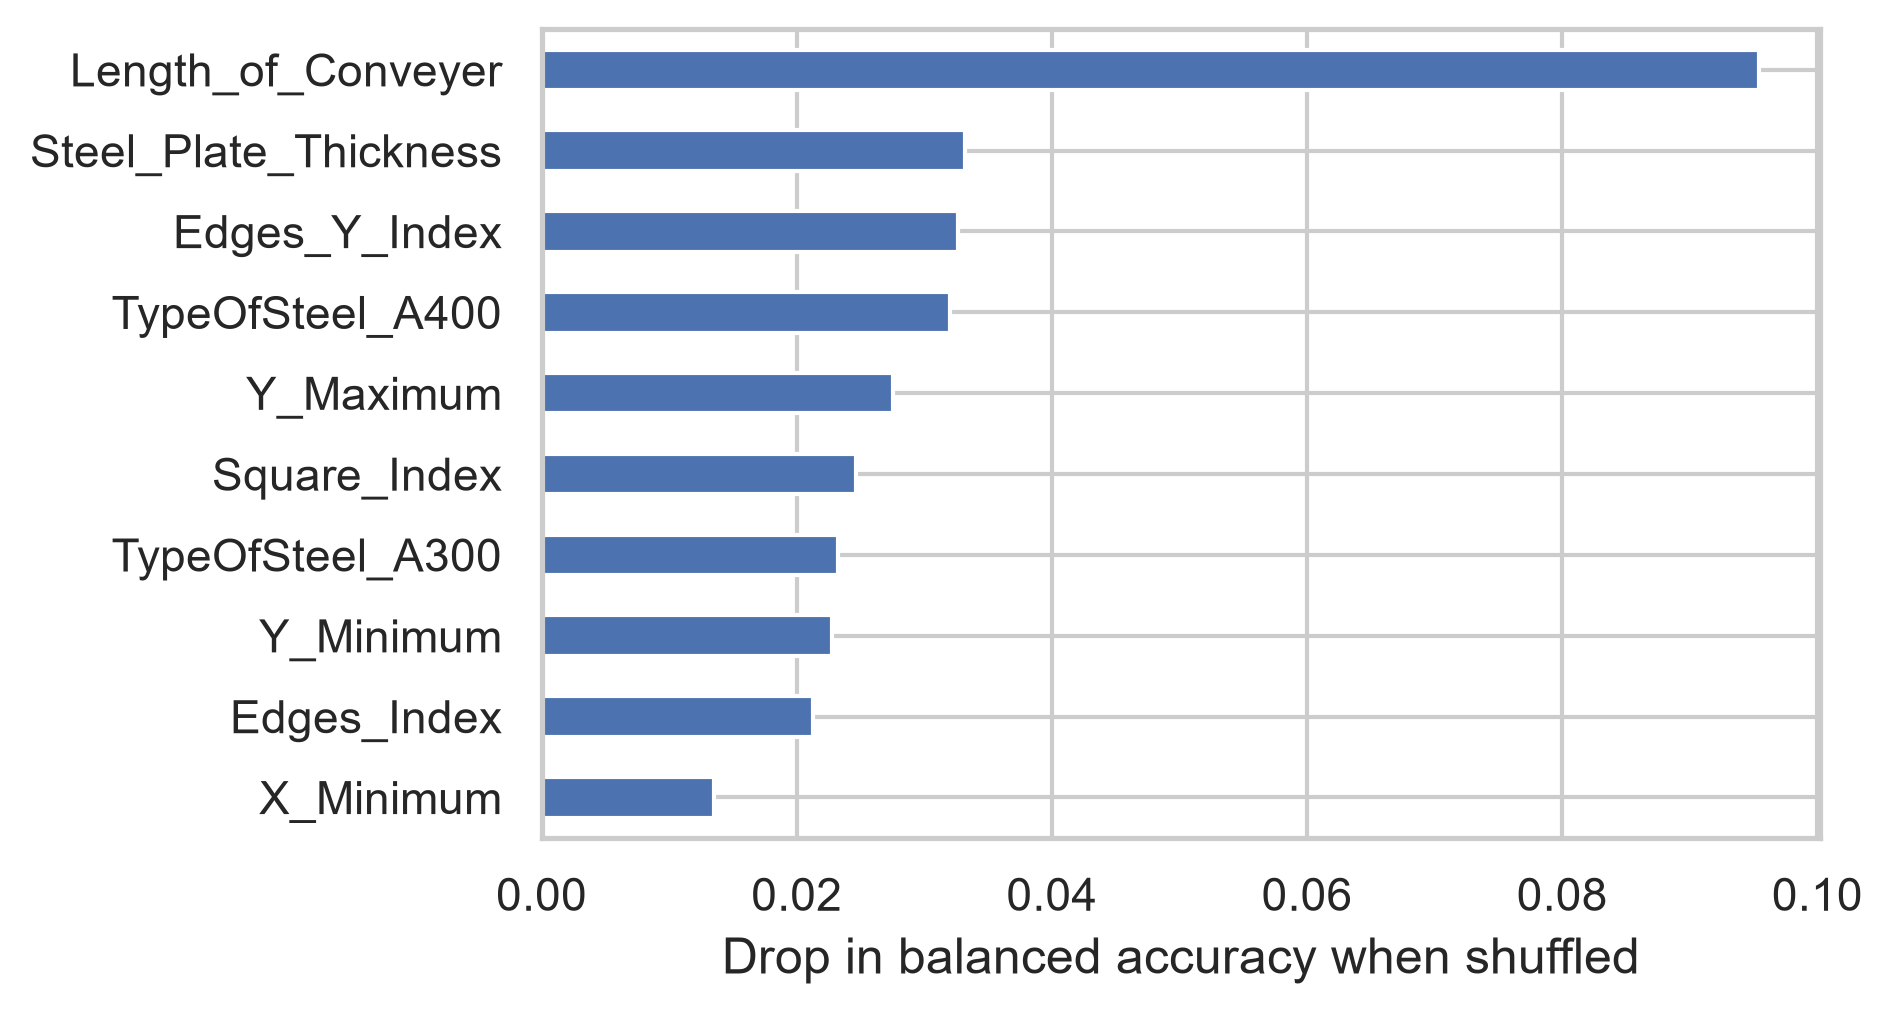

In [5]:
#| code-fold: false
from sklearn.inspection import permutation_importance

pi = permutation_importance(rf, X_test, y_test, n_repeats=10, random_state=0,
                            scoring="balanced_accuracy")
imp = pd.Series(pi.importances_mean, index=X.columns).sort_values()
imp.tail(10).plot.barh(xlabel="Drop in balanced accuracy when shuffled")
plt.show()

Feature: Length_of_Conveyer


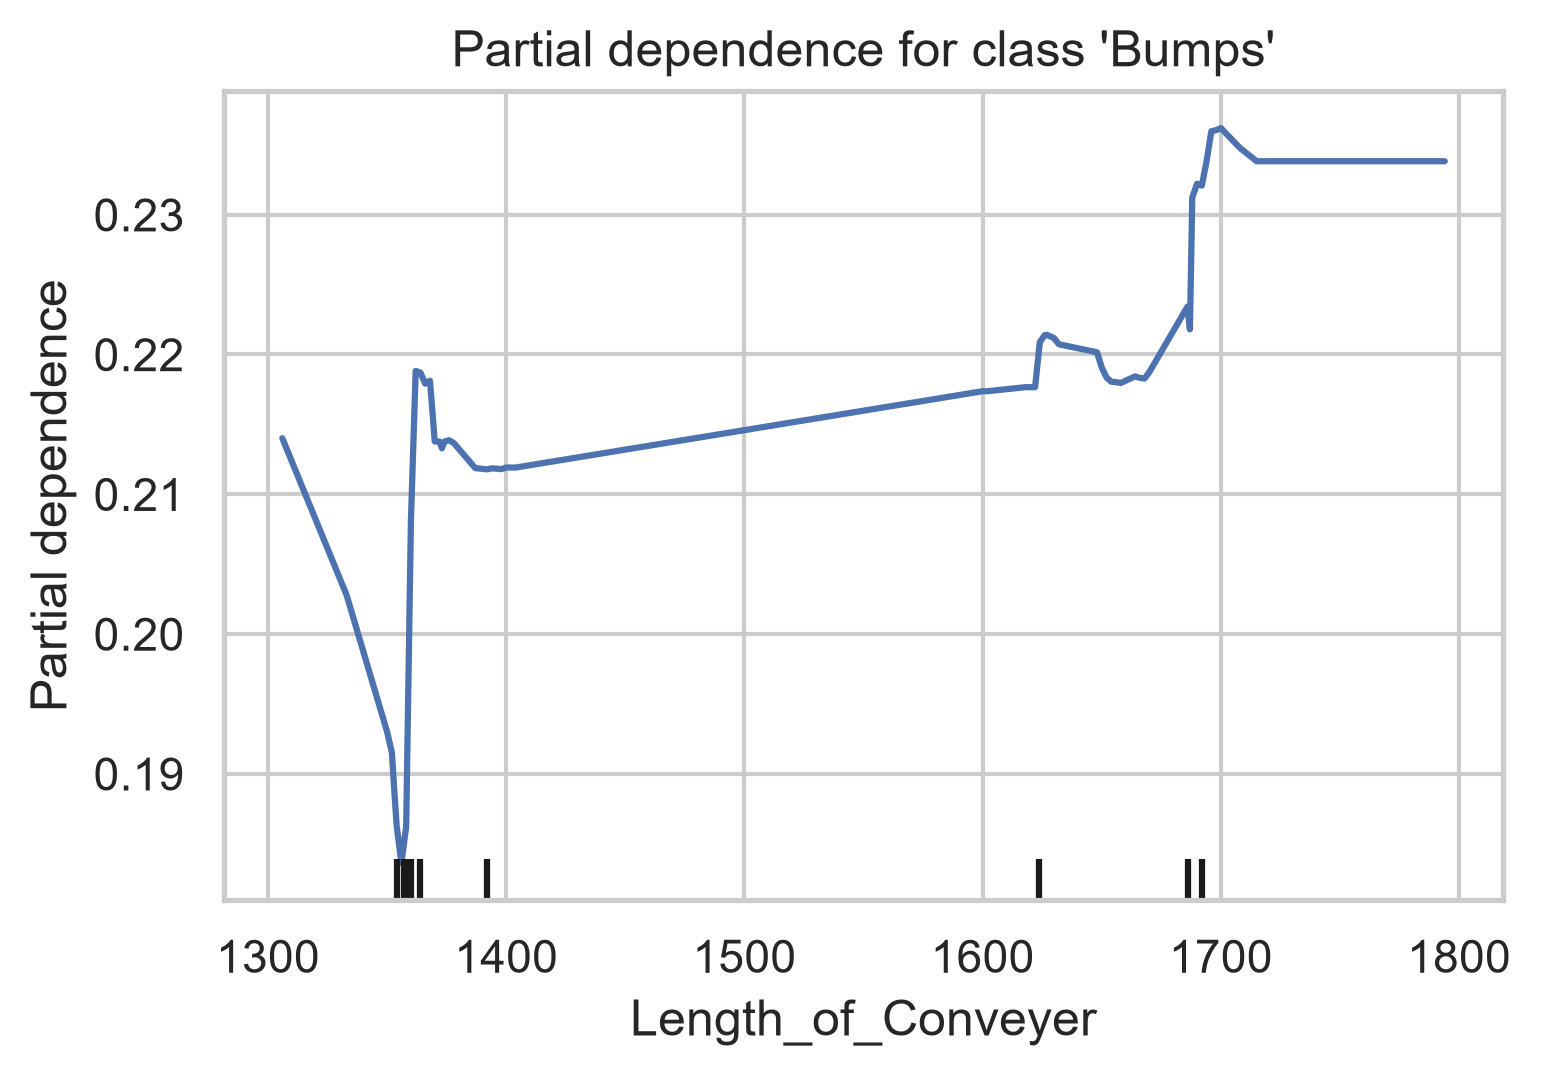

In [6]:
#| code-fold: false
from sklearn.inspection import PartialDependenceDisplay

# The most important feature with a continuous range of values (binary features such as
# the steel type have no meaningful curve). Partial dependence needs floating-point data.
top = next(c for c in imp.index[::-1] if X_test[c].nunique() > 10)
print("Feature:", top)
PartialDependenceDisplay.from_estimator(rf, X_test.astype(float), [top], target=rf.classes_[0], kind="average")
plt.title(f"Partial dependence for class '{rf.classes_[0]}'")
plt.show()

**Discussion.** The importance ranking tells us which measurements the model relies on – for steel defects typically luminosity and geometry features as well as the steel type and plate thickness. The partial dependence plot shows *how* the predicted probability of one class changes along the most important continuous feature. Look for thresholds: a steep step suggests a physical limit or a property of the inspection system worth discussing with the process engineers.

## Back to the decision

For each class we need both high precision (when the model says "scratch", it really is one) and high recall (it finds the scratches). We read both from the test set and apply the 90 % criterion.

In [7]:
#| code-fold: false
from sklearn.metrics import precision_recall_fscore_support

prec, rec, _, support = precision_recall_fscore_support(y_test, rf.predict(X_test), labels=rf.classes_, zero_division=0)
per_class = pd.DataFrame({"precision": prec, "recall": rec, "test cases": support}, index=rf.classes_)
per_class["automate"] = (per_class["precision"] >= 0.9) & (per_class["recall"] >= 0.9)
print(per_class.round(2))
share = per_class.loc[per_class["automate"], "test cases"].sum() / per_class["test cases"].sum()
auto = list(per_class.index[per_class["automate"]])
print(f"Decision: automate {auto if auto else 'no class yet'} – about {share:.0%} of the defects would no longer need an inspector.")

              precision  recall  test cases  automate
Bumps              0.77    0.73         101     False
Dirtiness          0.83    0.71          14     False
K_Scratch          0.97    0.91          98      True
Other_Faults       0.69    0.80         168     False
Pastry             0.66    0.54          39     False
Stains             1.00    0.94          18      True
Z_Scratch          0.93    0.81          48     False
Decision: automate ['K_Scratch', 'Stains'] – about 24% of the defects would no longer need an inspector.


With only a few dozen test cases per class, precision and recall are themselves uncertain – a class that just passes the 90 % mark should be monitored closely after go-live, for example by having inspectors check a random sample of automatically classified plates. Classes that fail the criterion are good candidates for better labels or additional features.

## Extension: SHAP values

*Extension – optional material, not required for the exam.*

SHAP (*SHapley Additive exPlanations*) distributes a single prediction among the features, based on the Shapley value from cooperative game theory: each feature receives its average marginal contribution over all possible orders in which features could be added. The contributions add up exactly to the difference between the prediction and the average prediction. SHAP answers the question: *why* did the model classify **this** plate as K_Scatch?

SHAP values for class: Bumps


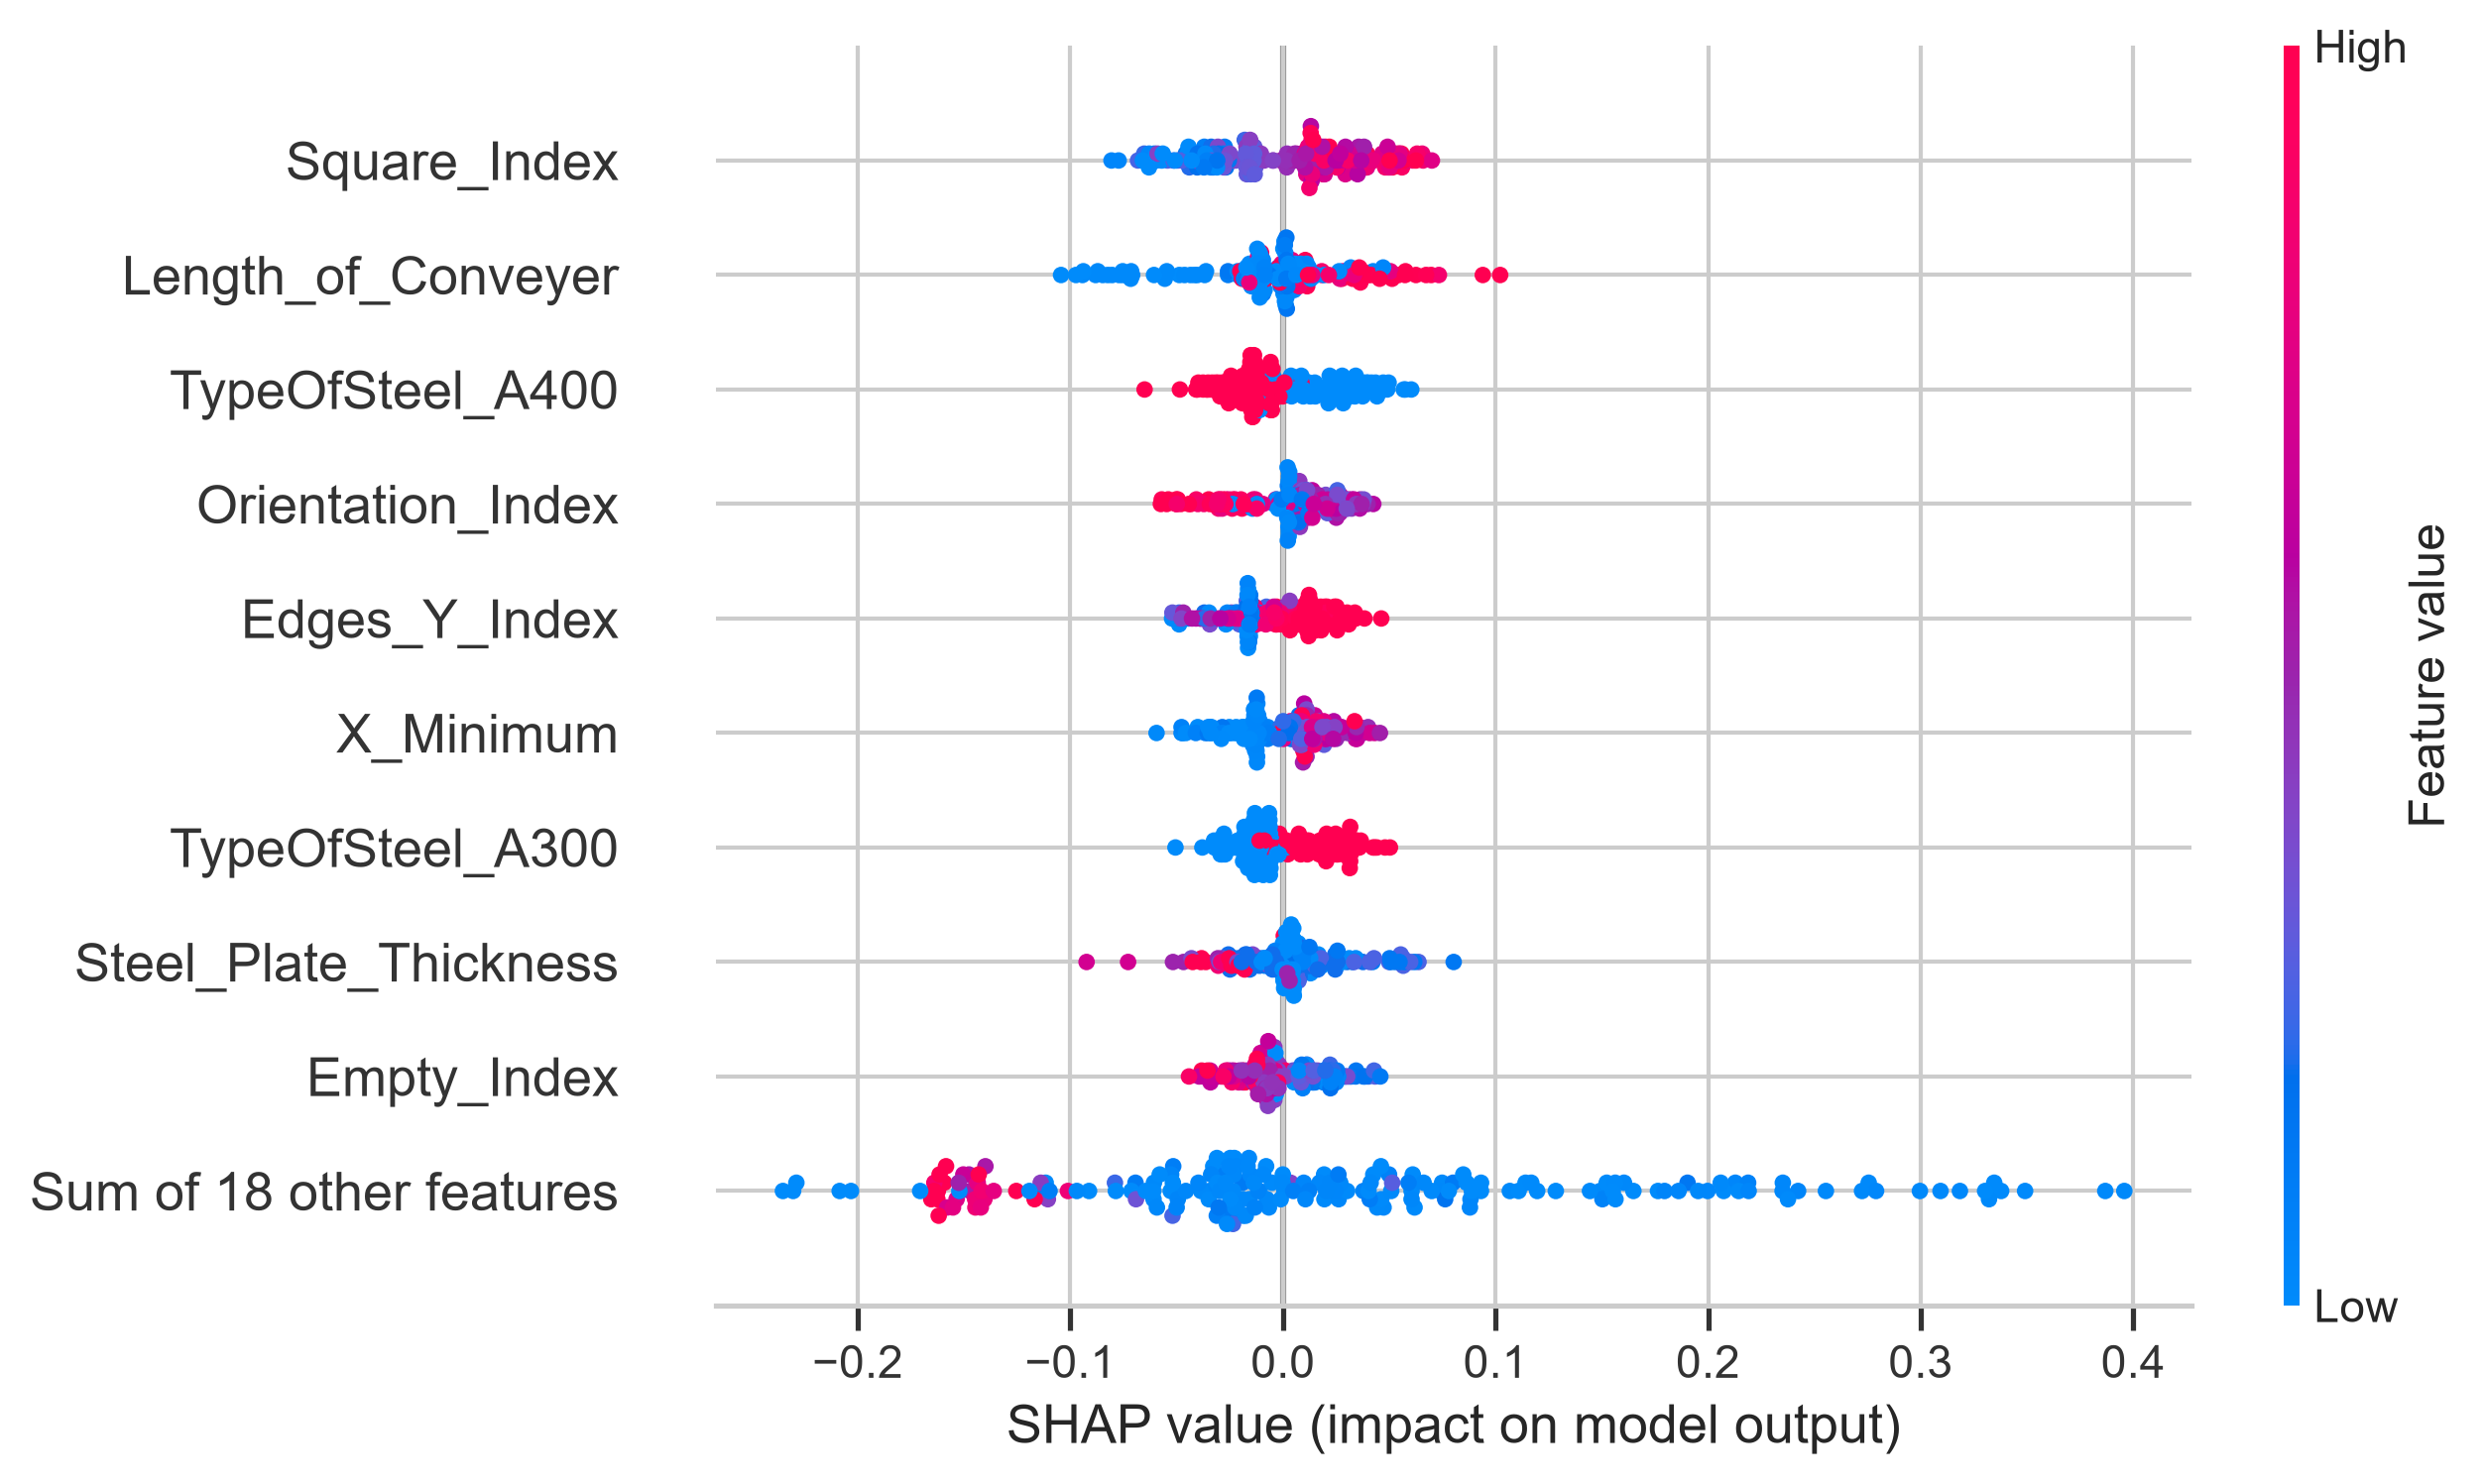

In [8]:
import shap

explainer = shap.TreeExplainer(rf)
sv = explainer(X_test.iloc[:200])
# SHAP values for one class, e.g. "K_Scatch"
cls = list(rf.classes_).index("K_Scatch") if "K_Scatch" in rf.classes_ else 0
print("SHAP values for class:", rf.classes_[cls])
shap.plots.beeswarm(sv[:, :, cls], max_display=10)

Each dot is one plate; its horizontal position is the contribution of the feature to the K_Scatch score, its colour the feature value. Features at the top have the largest overall influence. Unlike permutation importance, the beeswarm plot also shows the *direction* of the effect.

::: {.callout-important}
## Key takeaways
- Bagging/random forests reduce variance by averaging decorrelated deep trees; boosting reduces bias by adding shallow trees sequentially.
- Random forests are robust defaults; gradient boosting needs tuning but is often slightly more accurate.
- In multi-class problems, use per-class metrics and the confusion matrix; macro averages protect rare classes.
- Permutation importance and partial dependence make black-box models inspectable – but importance is not causality.
:::

## Exercises

<div class="exercises">

1. Tune `max_depth`, `learning_rate` and `max_iter` of the gradient boosting model with `RandomizedSearchCV`. How much does the tuning gain compared with the default?
2. Which fault classes are confused most often? Look at the row-normalised confusion matrix and discuss whether the confusions are plausible.
3. Compare impurity-based importance (`rf.feature_importances_`) with permutation importance. Why can they differ?
4. Train the random forest with `class_weight="balanced"`. How do the recalls of the rare classes *Dirtiness* and *Stains* change?
5. (Extension) Explain one single prediction with a SHAP waterfall plot, as you would to a quality engineer.

</div>

### Solutions

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 1

In [9]:
#| code-fold: false
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform, randint

search = RandomizedSearchCV(
    HistGradientBoostingClassifier(random_state=0),
    {"learning_rate": loguniform(0.01, 0.3), "max_depth": randint(2, 10),
     "max_iter": randint(100, 600), "l2_regularization": loguniform(1e-4, 1)},
    n_iter=25, cv=cv, scoring="balanced_accuracy", random_state=0, n_jobs=-1)
search.fit(X_train, y_train)
print("best parameters:", search.best_params_)
print(f"CV balanced accuracy: tuned {search.best_score_:.3f}")

best parameters: {'l2_regularization': np.float64(0.028079081078857277), 'learning_rate': np.float64(0.0815241575370242), 'max_depth': 9, 'max_iter': 488}
CV balanced accuracy: tuned 0.783


Random search samples hyperparameter combinations instead of trying a full grid – usually more efficient when only a few parameters matter. The gain over the default is often modest (a few percentage points); compare it with the fold-to-fold standard deviation before concluding that tuning was worthwhile. The CV score of the best configuration is slightly optimistic, because it was selected among 25 candidates – an untouched test set gives the honest estimate.
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 2
The largest off-diagonal entries of the normalised confusion matrix show the most frequent confusions. Typically, *Other_Faults* is confused with *Bumps* and vice versa: both are less distinct in shape, and "other" is a collection of different defect types without a common signature. Geometrically clear defects such as *K_Scatch* or *Pastry* are rarely confused. From a process point of view, refining the *Other_Faults* category (better labels) may improve the classification more than any change of the algorithm.
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 3

In [10]:
#| code-fold: false
cmp = pd.DataFrame({"impurity": pd.Series(rf.feature_importances_, index=X.columns),
                    "permutation": imp})
cmp.rank(ascending=False).sort_values("permutation").head(10)

,impurity,permutation
Length_of_Conveyer,2.0,1.0
Steel_Plate_Thickness,6.0,2.0
Edges_Y_Index,18.0,3.0
TypeOfSteel_A400,25.0,4.0
Y_Maximum,17.0,5.0
Square_Index,14.0,6.0
TypeOfSteel_A300,26.0,7.0
Y_Minimum,19.0,8.0
Edges_Index,13.0,9.0
X_Minimum,8.0,10.0


Impurity importance is computed on the training data during tree building and favours continuous features with many possible split points; it also distributes importance over correlated features. Permutation importance is computed on test data and measures what the model actually needs for its predictions. Strongly correlated features (e.g. different measures of the defect size) can have high impurity importance but low permutation importance, because shuffling one leaves the others intact.
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 4

In [11]:
#| code-fold: false
from sklearn.metrics import recall_score

rf_bal = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=0, n_jobs=-1)
rf_bal.fit(X_train, y_train)
pd.DataFrame({
    "recall (unweighted)": recall_score(y_test, rf.predict(X_test), average=None, labels=rf.classes_),
    "recall (balanced)": recall_score(y_test, rf_bal.predict(X_test), average=None, labels=rf.classes_),
}, index=rf.classes_).round(2)

,recall (unweighted),recall (balanced)
Bumps,0.73,0.81
Dirtiness,0.71,0.86
K_Scratch,0.91,0.91
Other_Faults,0.80,0.62
Pastry,0.54,0.77
Stains,0.94,1.00
Z_Scratch,0.81,0.92


Class weights often increase the recall of rare classes slightly at the expense of frequent ones. For random forests the effect is usually small, because deep trees fit even small classes in the training data. With few test examples per rare class (only a dozen or so), recall estimates are very uncertain – one more or one fewer correct plate changes them by several percentage points.
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 5

predicted class: Stains  true class: Stains


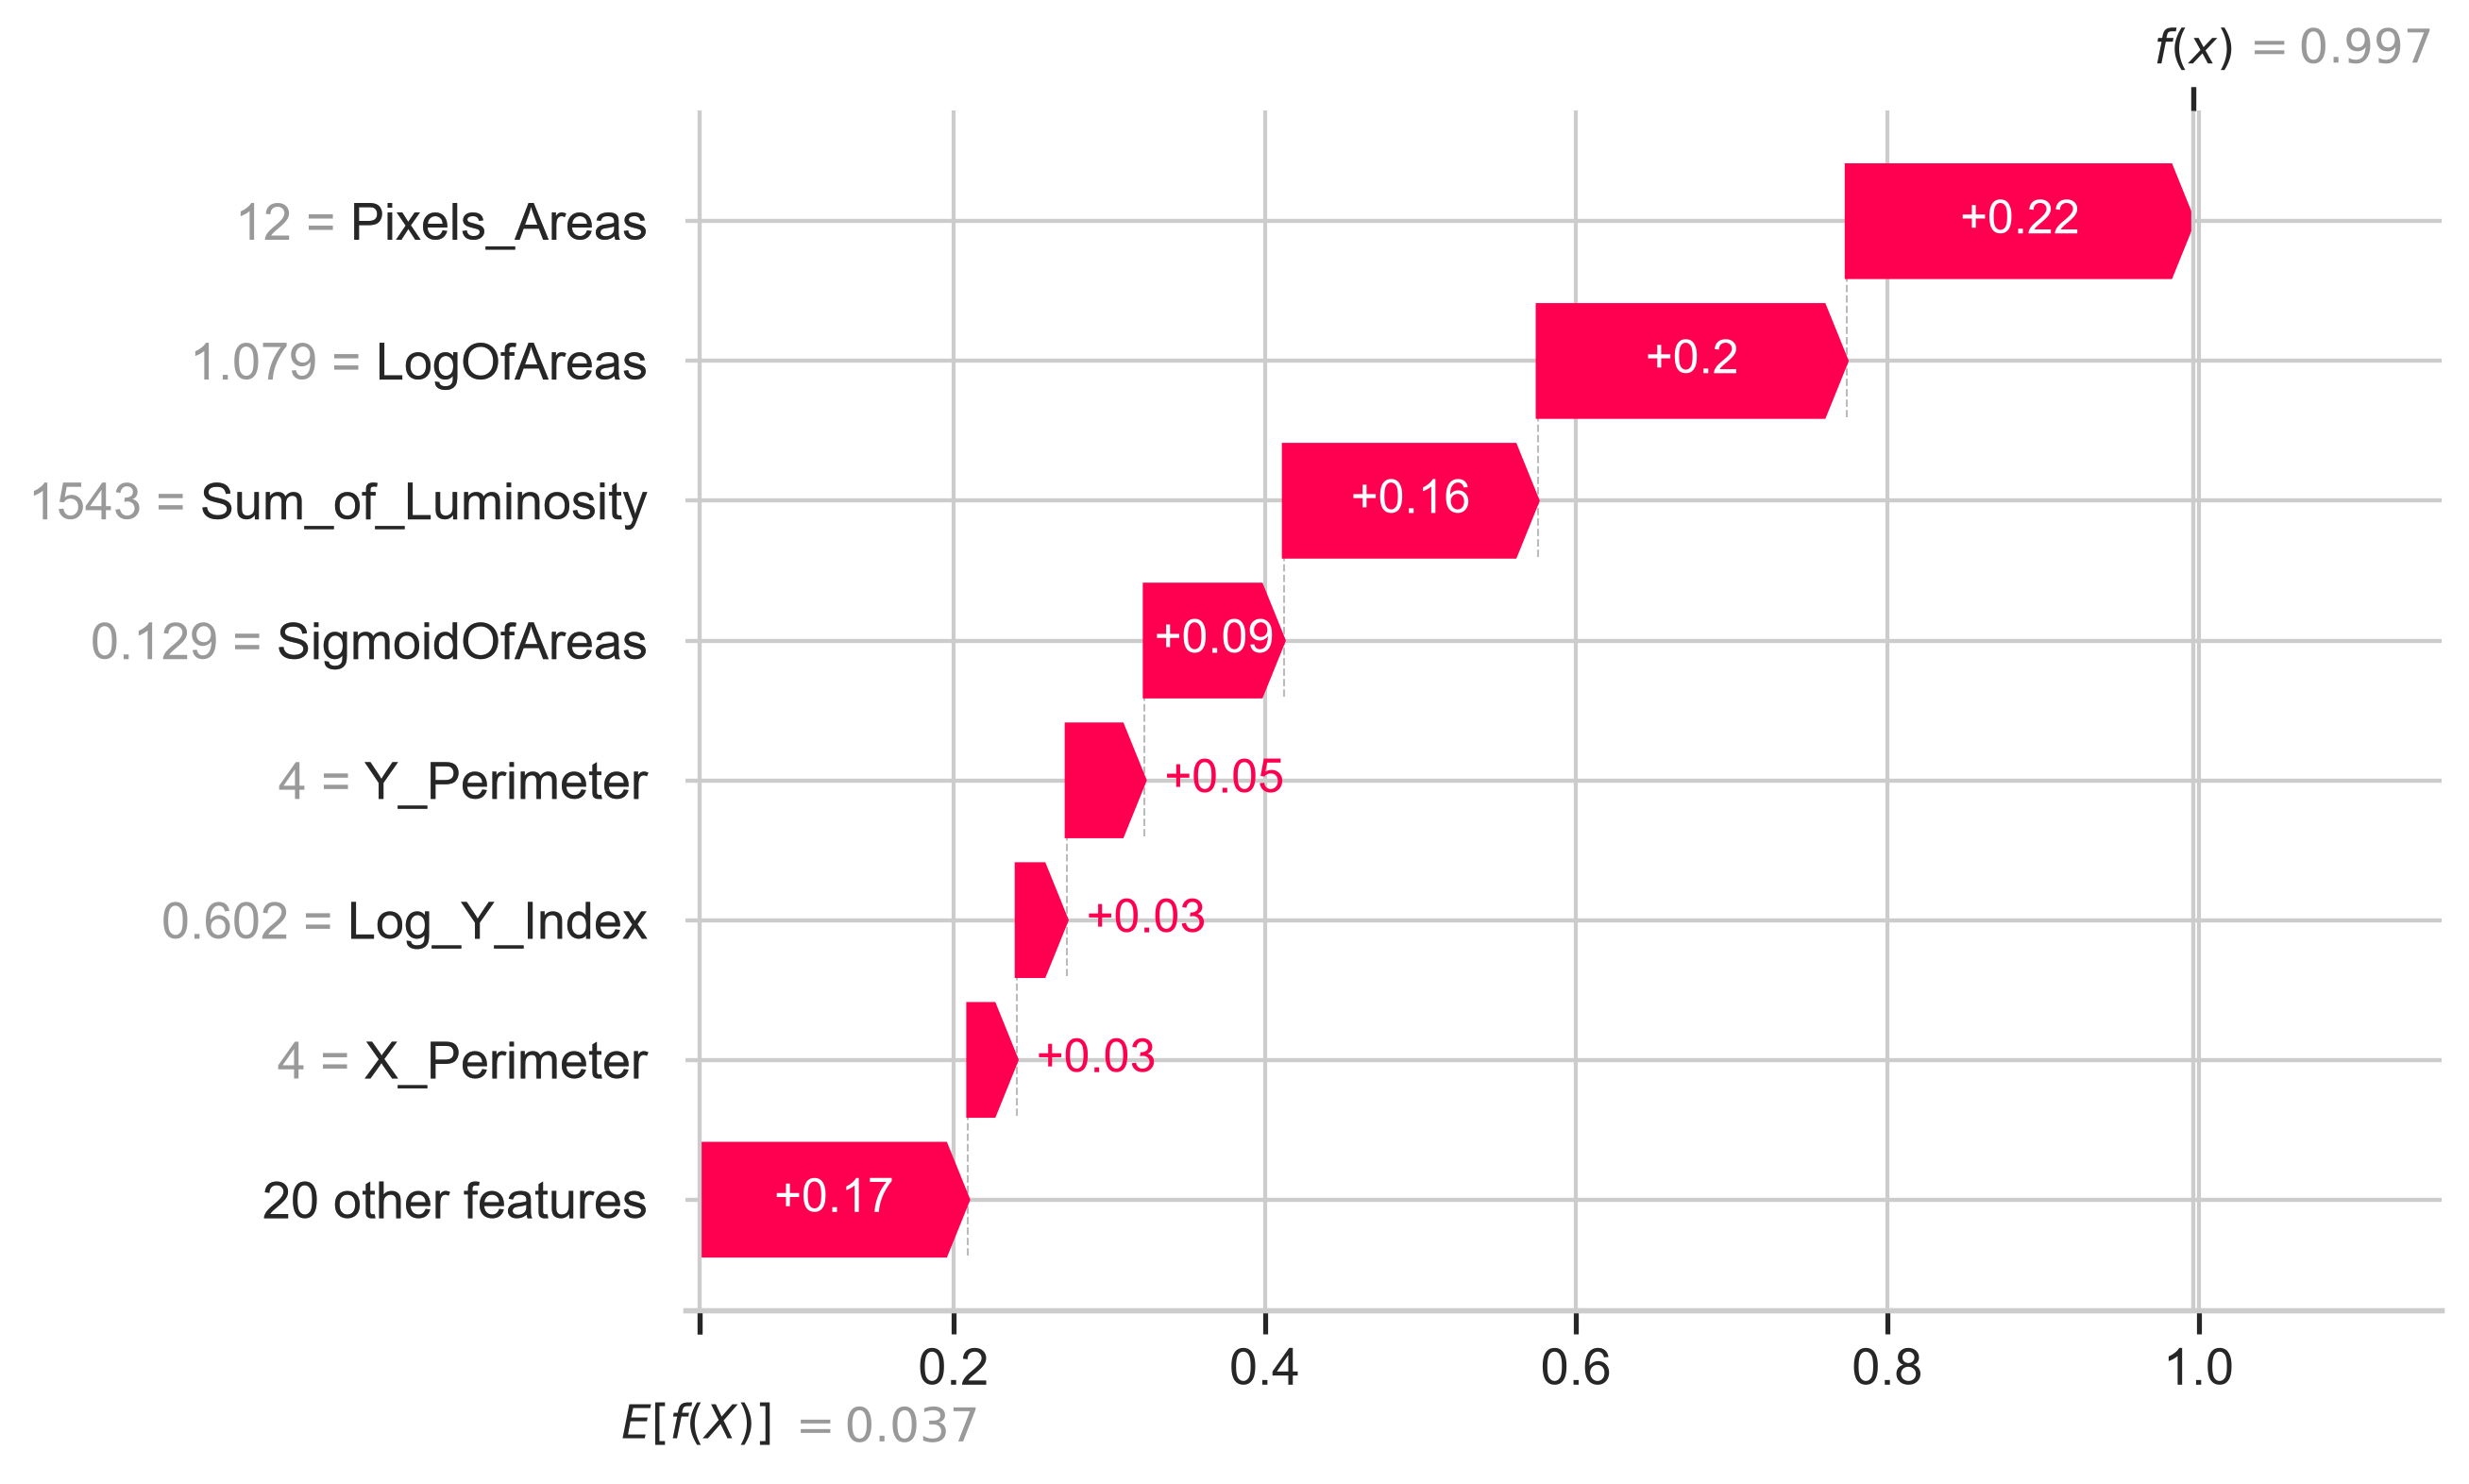

In [12]:
#| code-fold: false
i = 0
pred_class = rf.predict(X_test.iloc[[i]])[0]
k = list(rf.classes_).index(pred_class)
print("predicted class:", pred_class, " true class:", y_test.iloc[i])
shap.plots.waterfall(sv[i, :, k], max_display=8)

The waterfall plot starts at the average model output for this class and adds the contribution of each feature until the prediction for this plate is reached. A good explanation for a quality engineer names the two or three largest contributions in physical terms, for example: "The model considers this a scratch mainly because the defect is long and narrow and its luminosity is low – typical for K_Scatch." It should also state what the explanation is *not*: a causal statement about the production process.
:::